# 04 - Customer Lifetime Value, Value at Risk & Recommendations

**Goal:** turn churn predictions into money and clear actions.

Run `python src/pipeline.py` first so `data/processed/customer_scores.csv` exists.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.append("../src")          # lets us reuse helper functions from src/pipeline.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
sc = pd.read_csv("../data/processed/customer_scores.csv")
print(f"{len(sc):,} customers scored")
sc[["customer_id", "segment", "churn_prob", "risk_level", "expected_annual_value", "risk_adjusted_clv", "value_at_risk"]].head()

1,699 customers scored


,customer_id,segment,churn_prob,risk_level,expected_annual_value,risk_adjusted_clv,value_at_risk
0,1,Loyal Customers,0.16,Low,"3,552.97","2,996.86",556.12
1,2,Lost / Hibernating,1.00,High,0.00,0.00,0.00
2,4,Loyal Customers,0.17,Low,"1,164.42",972.21,192.21
3,5,Loyal Customers,0.32,Low,"1,657.58","1,134.86",522.72
4,6,At Risk,0.84,High,"1,722.26",275.30,"1,446.96"


## 1. How the value numbers are calculated (transparent heuristics)
- **Expected annual value** = average order value x orders per year (from the customer's own history)
- **Value at risk** = expected annual value x churn probability
- **Risk-adjusted CLV** = expected annual value x (1 - churn probability)

These are simple, explainable estimates. The README lists probabilistic CLV (BG/NBD) as a future improvement.

In [3]:
risk = sc.groupby("risk_level")[["customer_id"]].count().rename(columns={"customer_id": "customers"})
risk["value_at_risk"] = sc.groupby("risk_level")["value_at_risk"].sum()
risk.reindex(["Low", "Medium", "High"])

,customers,value_at_risk
risk_level,,
Low,835,"208,060.16"
Medium,200,"92,436.37"
High,664,"358,083.90"


## 2. Where is the money at risk?

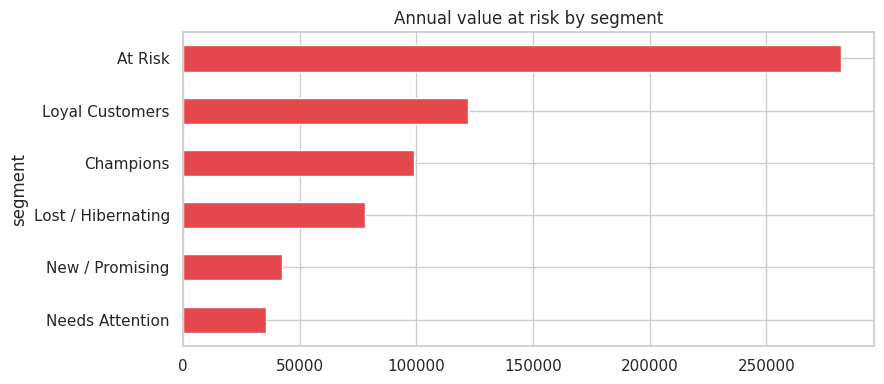

,customers,avg_churn_prob,value_at_risk,risk_adj_clv
segment,,,,
At Risk,332,0.93,"281,961.47","25,915.21"
Loyal Customers,319,0.27,"121,935.28","358,738.79"
Champions,368,0.13,"99,125.15","778,554.60"
Lost / Hibernating,348,0.95,"77,852.06","6,206.44"
New / Promising,191,0.18,"42,261.21","168,666.72"
Needs Attention,141,0.36,"35,445.25","66,263.92"


In [4]:
seg = sc.groupby("segment").agg(customers=("customer_id", "size"), avg_churn_prob=("churn_prob", "mean"),
                                 value_at_risk=("value_at_risk", "sum"), risk_adj_clv=("risk_adjusted_clv", "sum"))
seg = seg.sort_values("value_at_risk", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
seg["value_at_risk"].sort_values().plot.barh(ax=ax, color="#E5484D"); ax.set_title("Annual value at risk by segment")
plt.tight_layout()
seg.round(2)

## 3. Priority list: high-value customers likely to churn

In [5]:
top = sc[sc["risk_level"] == "High"].sort_values("expected_annual_value", ascending=False).head(15)
top[["customer_id", "segment", "recency", "frequency", "churn_prob", "expected_annual_value"]].round(2).reset_index(drop=True)

,customer_id,segment,recency,frequency,churn_prob,expected_annual_value
0,1009,At Risk,202,56,0.97,"5,972.46"
1,534,At Risk,196,38,0.98,"5,031.39"
2,1564,At Risk,93,18,0.74,"4,900.23"
3,1449,At Risk,118,23,0.82,"4,857.05"
4,604,At Risk,226,49,0.98,"4,455.47"
5,1248,At Risk,227,25,0.99,"4,079.57"
6,790,At Risk,186,17,0.96,"3,309.88"
7,2163,At Risk,100,65,0.86,"3,297.34"
8,2132,At Risk,225,18,0.97,"3,154.43"
9,2043,Loyal Customers,68,24,0.71,"3,149.42"


## 4. Retention opportunity (illustrative scenario)
**Assumption (change it!):** a win-back campaign recovers 15% of the value at risk among *High*-risk customers.

In [6]:
RECOVERY_RATE = 0.15
high_var = sc.loc[sc["risk_level"] == "High", "value_at_risk"].sum()
print(f"Value at risk (High-risk customers): {high_var:,.0f}")
print(f"Recoverable at {RECOVERY_RATE:.0%} success rate: {high_var * RECOVERY_RATE:,.0f}")

Value at risk (High-risk customers): 358,084
Recoverable at 15% success rate: 53,713


## 5. Recommended actions by segment

In [7]:
actions = {
    "Champions": "Reward and retain: loyalty tier, early access, referral programme",
    "Loyal Customers": "Grow basket size: cross-sell, bundles, subscription offers",
    "New / Promising": "Win the second order: onboarding email series, 30-day incentive",
    "Needs Attention": "Re-engage: personalised recommendations, reminder of past favourites",
    "At Risk": "Win-back priority: personal outreach, time-limited offer, feedback survey",
    "Lost / Hibernating": "Low-cost reactivation only; stop spending if no response",
}
plan = seg[["customers", "avg_churn_prob", "value_at_risk"]].copy()
plan["action"] = plan.index.map(actions)
plan.round(2)

,customers,avg_churn_prob,value_at_risk,action
segment,,,,
At Risk,332,0.93,"281,961.47","Win-back priority: personal outreach, time-limited offer, feedback survey"
Loyal Customers,319,0.27,"121,935.28","Grow basket size: cross-sell, bundles, subscription offers"
Champions,368,0.13,"99,125.15","Reward and retain: loyalty tier, early access, referral programme"
Lost / Hibernating,348,0.95,"77,852.06",Low-cost reactivation only; stop spending if no response
New / Promising,191,0.18,"42,261.21","Win the second order: onboarding email series, 30-day incentive"
Needs Attention,141,0.36,"35,445.25","Re-engage: personalised recommendations, reminder of past favourites"


### Key takeaways
- **At Risk** customers are about 20% of customers but about 43% of the annual value at risk - target them first.
- *High*-risk customers are 39% of customers but 54% of the value at risk, so contacting only high-risk, high-value customers keeps campaign cost down.
- Re-score customers monthly and track whether campaigns actually move churn (A/B test).